<a href="https://colab.research.google.com/github/paulter19/Anonymous/blob/master/data_analysis_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#this reads csv file with pandas, on_bad_lines ='skip' skips line invalid data
df = pd.read_csv('products_asos.csv', on_bad_lines='skip')

#clean price column make sure its numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

#get length of rows
print(f"Data Loaded: {len(df)} rows")

df.head()









Data Loaded: 18378 rows


,url,name,size,category,price,color,sku,description,images
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,123650194.0,[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...


/tmp/ipykernel_1079/1517370958.py:77: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


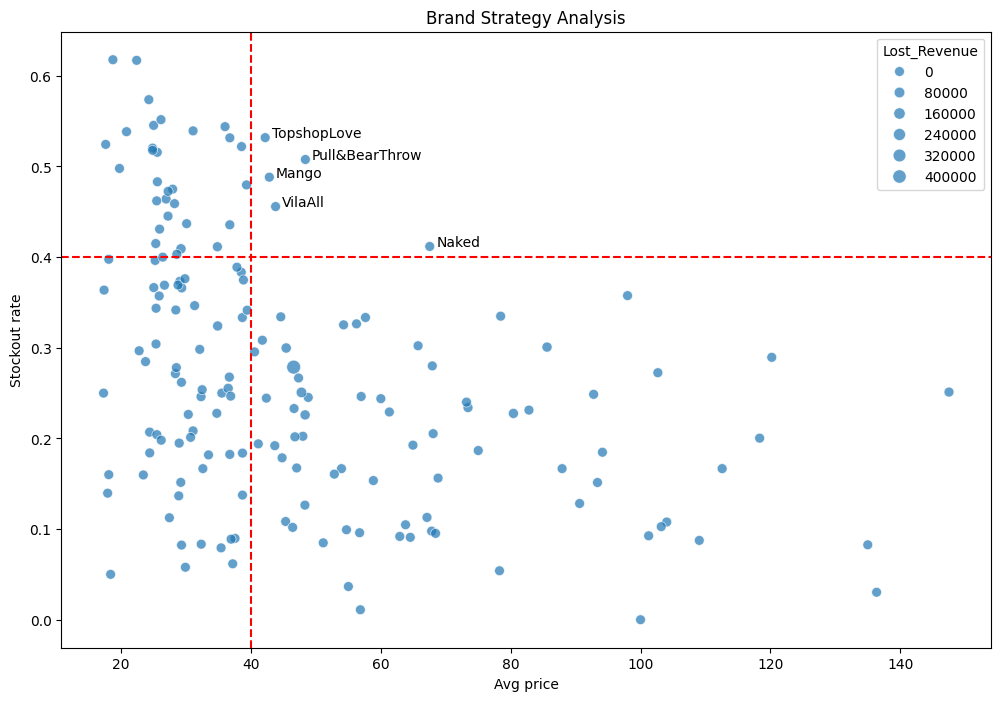

In [50]:
df['description'] = df['description'].astype(str)


def get_brand(text):
  if 'by' in text:
    try:
      return text.split('by ')[1].split(' ')[0]
    except:
      return "unknown"
  return "Unknown"


## apply applys the function to the object in this case string
df['brand_raw'] = df['description'].apply(get_brand)

#create mapping if you see new change to new look etc
brand_map = {
    'New': 'New Look',
    'River': 'River Island',
    'Miss': 'Miss Selffridge',
    'TopshopWelcome': 'Topshop',
}

#fillna replaces null values with parameter this case orig brand_raw
df['Brand'] = df['brand_raw'].map(brand_map).fillna(df['brand_raw'])


brand_counts = df['Brand'].value_counts()

valid_brands = brand_counts[brand_counts >5].index

df_clean = df[df['Brand'].isin(valid_brands)].copy()

#head is amount to return
#print(df_clean['Brand'].value_counts().head(5))
df.head(3)

#this function analyze stockouts
def calculate_phantom_revenue(size_str):
  if not isinstance(size_str, str):
    return 0, 0,0

  #split sizes into list
  sizes = size_str.split(',')
  total_sizes = len(sizes)

  #count how many out of stock
  out_of_stock_count = size_str.count('Out of stock')

  #Calculate Rate 0.0 to 1.0
  rate = out_of_stock_count / total_sizes if total_sizes > 0 else 0.0

  return out_of_stock_count, rate

metrics = df_clean['size'].apply(lambda x: calculate_phantom_revenue(x))

df_clean['Stockout_Count'] = [x[0] for x in metrics ]
df_clean['Stockout_Rate'] = [x[1] for x in metrics ]

df_clean['Lost_Revenue'] = df_clean['price'] * df_clean['Stockout_Count']

cols = ['Brand', 'name', 'price', 'Stockout_Count', 'Lost_Revenue']

#print top 5 lost revenue
#print(df_clean.sort_values(by='Lost_Revenue', ascending=False).head(5)[cols])

brand_strategy = df_clean.groupby('Brand').agg({
    'price': 'mean',
    'Stockout_Rate': 'mean',
    'Lost_Revenue':'sum',
    'name':'count'
}).reset_index()

brand_strategy = brand_strategy[brand_strategy['name'] > 10]

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=brand_strategy,
    x='price',
    y='Stockout_Rate',
    size='Lost_Revenue',
    sizes=(50,100),
    alpha=0.7,
    palette='viridis'
)

winners = brand_strategy[
    (brand_strategy['price'] > 40) &
    (brand_strategy['Stockout_Rate'] > 0.4)
]

for i in range(len(winners)):
  plt.text(
      winners.iloc[i]['price']+1,
      winners.iloc[i]['Stockout_Rate'],
      winners.iloc[i]['Brand'],
  )

plt.title('Brand Strategy Analysis')
plt.xlabel("Avg price")
plt.ylabel("Stockout rate")
plt.axvline(x=40, color='red', linestyle='--')
plt.axhline(y=0.4, color='red', linestyle='--')
plt.show()

#graph shows most inventory clustered in lower right low stockout rate
#top right are brands customers willing to pay prenium and selling out faster than restock








